# Local sensitivity analysis

How strongly do the KPIs of a cycle depend on its inputs? This notebook computes normalised local sensitivities by central finite differences:

$$S_{ij} = \frac{\partial \ln y_i}{\partial \ln x_j} \approx \frac{y_i(x_j(1+h)) - y_i(x_j(1-h))}{2h\,y_i(x_j)}$$

for KPIs $y_i$ (CO₂ purity and recovery) and parameters $x_j$, with a relative step $h = 5\%$. $S = 1$ means a 1 % change in the parameter gives a 1 % change in the KPI.

The deck is the shipped example `Perez2019_A.json` (a four-step CO₂ VSA cycle). The parameters are perturbed one at a time, so 2 runs per parameter plus the base run. Every run uses the same fixed number of cycles (15), so the comparison is between equally converged states; this is a fast screening, not a cyclic-steady-state result.

In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import skarstrom

plt.rcParams["figure.dpi"] = 80
print("skarstrom", skarstrom.__version__)

skarstrom 0.1.0


In [2]:
base = skarstrom.examples.Perez2019_A.load()
base.cycle.number_of_cycles = 15
base.css.method = 0             # no early stop: every run does exactly 15 cycles
tunable = {p.path: p for p in base.parameters(tunable_only=True)}
len(tunable)

50

Pick a handful of parameters from the registry by their paths: the feed-step time, the feed velocity and the feed CO₂ mole fraction of the feed step's inlet stream, the bed void fraction and particle diameter of the first layer, and the CO₂ isotherm affinity of the adsorbent.

In [3]:
def first(pred):
    return next(p for p in tunable.values() if pred(p))

feed = base.steps[0].name
chosen = [
    first(lambda p: p.path.startswith("step[") and p.path.endswith(".time")),
    first(lambda p: p.alias.startswith(f"step[{feed}].") and p.path.endswith((".velocity", ".molar_flow", ".volumetric_flow", ".mass_flow"))),
    first(lambda p: p.alias.startswith(f"step[{feed}].") and p.path.endswith(".pressure")),
    first(lambda p: p.path.startswith("layer[") and p.path.endswith(".bed_void_fraction")),
    first(lambda p: p.path.startswith("layer[") and p.path.endswith(".particle_diameter")),
    first(lambda p: ".isotherm[CarbonDioxide]." in p.path and p.name in ("b1", "b", "k_A", "B1", "b0")),
]
pd.DataFrame([(p.path, p.alias, p.name, p.value, p.unit) for p in chosen],
             columns=["path", "alias", "name", "value", "unit"])

,path,alias,name,value,unit
0,step[1].time,step[Feed].time,step time,9.900000e+01,s
1,endpoint[1].velocity,step[Feed].bottom[Feed inlet].velocity,inlet velocity,8.487000e-02,m/s
2,endpoint[2].pressure,step[Feed].top.pressure,pressure (constant),1.000000e+05,Pa
3,layer[1].bed_void_fraction,layer[13X].bed_void_fraction,bed void fraction,4.100000e-01,-
4,layer[1].particle_diameter,layer[13X].particle_diameter,particle diameter,1.500000e-03,m
5,adsorbent[1].isotherm[CarbonDioxide].b1,adsorbent[13X].isotherm[CarbonDioxide].b1,b1,3.934000e-07,m3/mol


In [4]:
def kpis(sim):
    sim.run()
    k = sim.kpis(cycle=-1)[0]
    return np.array([k.purity, k.recovery])

y0 = kpis(base.copy())
h = 0.05
S = []
for p in chosen:
    up, down = base.copy(), base.copy()
    up[p.path] = p.value * (1 + h)
    down[p.path] = p.value * (1 - h)
    S.append((kpis(up) - kpis(down)) / (2 * h * y0))
S = pd.DataFrame(S, index=[p.alias for p in chosen], columns=["purity", "recovery"])
print("base purity %.4f, recovery %.4f" % tuple(y0))
S.round(3)

base purity 0.9869, recovery 0.6188


,purity,recovery
step[Feed].time,0.056,-0.025
step[Feed].bottom[Feed inlet].velocity,0.059,-0.040
step[Feed].top.pressure,0.051,0.199
layer[13X].bed_void_fraction,0.040,-0.048
layer[13X].particle_diameter,0.001,-0.014
adsorbent[13X].isotherm[CarbonDioxide].b1,0.002,-0.014


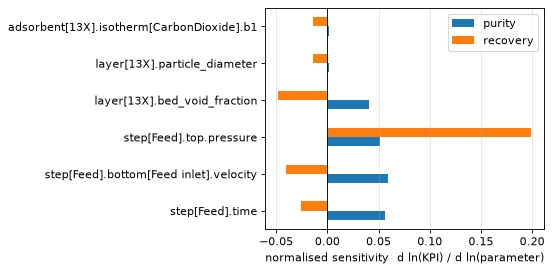

In [5]:
ax = S.plot.barh(figsize=(7, 3.5))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("normalised sensitivity  d ln(KPI) / d ln(parameter)")
ax.grid(alpha=0.3, axis="x")
plt.tight_layout()